# Part C: Practical Machine Learning (40 marks)
C1 Regression (wine quality) | C2 Classification (spambase) | C3 Clustering (glass)

Each section has its own imports, so it can be run on its own. Keep the three CSV files in the same folder as this notebook.

---
# C1. Regression on Wine Quality (red wine) — 15 marks

In [1]:
# C1 imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 7863

## 1. Load data and EDA (4 marks)

In [2]:
wine = pd.read_csv("winequality-red.csv", sep=";")   # this file uses ';' as separator
print("Shape:", wine.shape)
wine.head()

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
# summary statistics
wine.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


In [4]:
# missing values and duplicates
print("Missing values:", wine.isna().sum().sum())
print("Duplicate rows:", wine.duplicated().sum())

Missing values: 0
Duplicate rows: 240


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


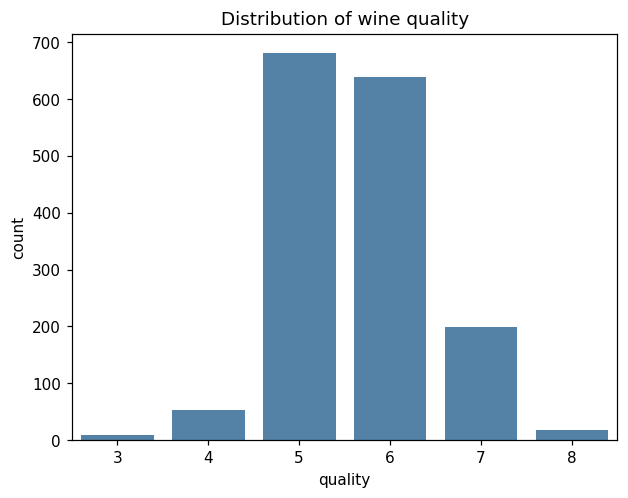

In [5]:
# distribution of the target (quality)
print(wine["quality"].value_counts().sort_index())
sns.countplot(x="quality", data=wine, color="steelblue")
plt.title("Distribution of wine quality")
plt.show()

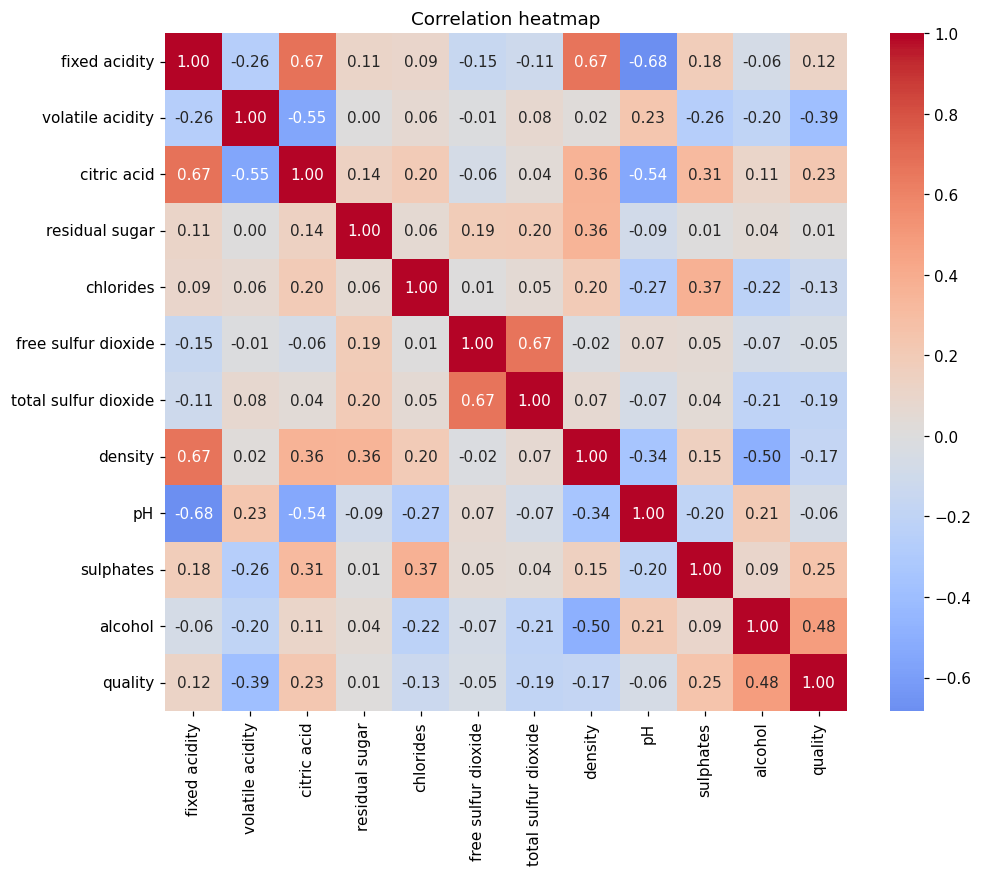

In [6]:
# correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(wine.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

**Findings:** There are no missing values and all columns are numeric. Quality is mostly 5 or 6 (681 and 638 wines), with very few 3s and 8s. Alcohol has the strongest positive correlation with quality (0.48) and volatile acidity the strongest negative (-0.39). Some features are correlated with each other (e.g. fixed acidity and density), which is where Ridge can help.

## 2. Preprocessing and split (3 marks)

In [7]:
# nothing to impute (no missing values) and nothing to encode (all numeric)
X = wine.drop(columns="quality")
y = wine["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1119, 11)  Test: (480, 11)


Features are on very different scales, so they are standardised. The scaler is put inside a pipeline so it is fitted on training data only (no leakage), also inside cross-validation.

## 3. Train models and test-set results (4 marks)

In [8]:
# Linear Regression
linear = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
linear.fit(X_train, y_train)

# Ridge Regression - alpha picked by 5-fold CV on the training set only
ridge_pipe = Pipeline([("scaler", StandardScaler()), ("model", Ridge())])
search = GridSearchCV(ridge_pipe, {"model__alpha": np.logspace(-3, 3, 31)}, cv=5, scoring="r2")
search.fit(X_train, y_train)
ridge = search.best_estimator_
print("Best alpha for Ridge:", round(search.best_params_["model__alpha"], 2))

Best alpha for Ridge: 63.1


In [9]:
# one table with MAE, RMSE and R-squared on the test set
rows = []
for name, model in [("Linear Regression", linear), ("Ridge Regression", ridge)]:
    pred = model.predict(X_test)
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(y_test, pred),
                 "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
                 "R-squared": r2_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Model")
results.round(4)

,MAE,RMSE,R-squared
Model,,,
Linear Regression,0.5091,0.6556,0.3171
Ridge Regression,0.5078,0.6534,0.3216


## 4. Actual vs predicted and 5-fold CV (2 marks)

Better model: Ridge Regression


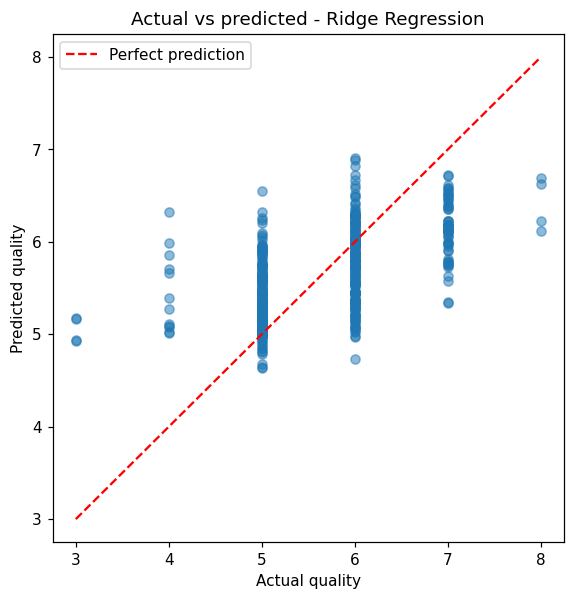

In [10]:
# plot for the better model (highest test R-squared)
best_name = results["R-squared"].idxmax()
best_model = ridge if best_name == "Ridge Regression" else linear
print("Better model:", best_name)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_model.predict(X_test), alpha=0.5)
plt.plot([3, 8], [3, 8], "r--", label="Perfect prediction")
plt.xlabel("Actual quality")
plt.ylabel("Predicted quality")
plt.title("Actual vs predicted - " + best_name)
plt.legend()
plt.show()

In [11]:
# 5-fold cross-validated R-squared for both models
kfold = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = {}
for name, model in [("Linear Regression", linear), ("Ridge Regression", ridge)]:
    scores = cross_val_score(model, X, y, cv=kfold, scoring="r2")
    cv_results[name] = {"Mean R-squared": scores.mean(), "Std": scores.std()}

pd.DataFrame(cv_results).T.round(4)

,Mean R-squared,Std
Linear Regression,0.3463,0.0481
Ridge Regression,0.3478,0.0456


## 5. Interpretation (2 marks)
**Ridge is the better model, but only by a very small margin.** On the test set it has slightly lower MAE (0.5078 vs 0.5091) and RMSE (0.6534 vs 0.6556) and a slightly higher R-squared (0.3216 vs 0.3171). The cross-validated R-squared agrees (0.3478 vs 0.3463), but the difference is much smaller than the fold-to-fold spread (about 0.05), so the two models are practically equal.

Ridge helps a little because it shrinks the coefficients of correlated features, which reduces variance. The gain is small because there are only 11 features and over 1,000 training rows. Both models explain only about a third of the variance, so the relationship is probably not purely linear; a non-linear model such as Random Forest would likely do better.

---
# C2. Classification on Spambase — 15 marks

In [12]:
# C2 imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve)

SEED = 7863

## 1. EDA (3 marks)

In [13]:
spam = pd.read_csv("spambase.csv")
print("Shape:", spam.shape, "(57 features + the 'spam' target)")
print("Missing values:", spam.isna().sum().sum())
print("Duplicate rows:", spam.duplicated().sum())
spam.describe().T.round(3).head(10)     # first 10 features shown to keep it short

Shape: (4601, 58) (57 features + the 'spam' target)
Missing values: 0
Duplicate rows: 391


,count,mean,std,min,25%,50%,75%,max
word_freq_make,4601.0,0.105,0.305,0.0,0.0,0.0,0.00,4.54
word_freq_address,4601.0,0.213,1.291,0.0,0.0,0.0,0.00,14.28
word_freq_all,4601.0,0.281,0.504,0.0,0.0,0.0,0.42,5.10
word_freq_3d,4601.0,0.065,1.395,0.0,0.0,0.0,0.00,42.81
word_freq_our,4601.0,0.312,0.673,0.0,0.0,0.0,0.38,10.00
word_freq_over,4601.0,0.096,0.274,0.0,0.0,0.0,0.00,5.88
word_freq_remove,4601.0,0.114,0.391,0.0,0.0,0.0,0.00,7.27
word_freq_internet,4601.0,0.105,0.401,0.0,0.0,0.0,0.00,11.11
word_freq_order,4601.0,0.090,0.279,0.0,0.0,0.0,0.00,5.26
word_freq_mail,4601.0,0.239,0.645,0.0,0.0,0.0,0.16,18.18


spam
0    2788
1    1813
Name: count, dtype: int64
spam
0    0.606
1    0.394
Name: proportion, dtype: float64


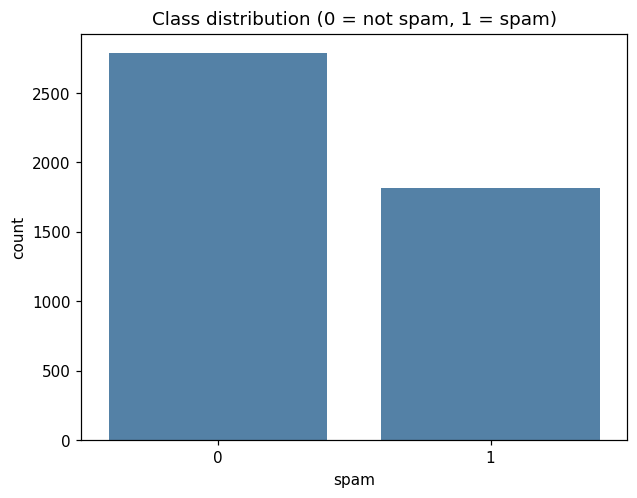

In [14]:
# class distribution (1 = spam, 0 = not spam)
print(spam["spam"].value_counts())
print(spam["spam"].value_counts(normalize=True).round(3))

sns.countplot(x="spam", data=spam, color="steelblue")
plt.title("Class distribution (0 = not spam, 1 = spam)")
plt.show()

In [15]:
# features most correlated with spam
corr = spam.corr()["spam"].drop("spam").sort_values()
print("Most negative:\n", corr.head(4).round(3))
print("\nMost positive:\n", corr.tail(4).round(3))

Most negative:
 word_freq_hp       -0.257
word_freq_hpl      -0.233
word_freq_george   -0.183
word_freq_1999     -0.178
Name: spam, dtype: float64

Most positive:
 char_freq_$         0.324
word_freq_remove    0.332
word_freq_000       0.335
word_freq_your      0.383
Name: spam, dtype: float64


**Findings:** No missing values and all features are numeric. The classes are mildly imbalanced (60.6% not spam, 39.4% spam), so a stratified split and stratified CV are used and accuracy alone is not enough. Words like "your", "000", "remove" and the "$" sign point to spam, while "hp", "hpl" and "george" point to normal email.

## 2. Preprocessing and stratified split (2 marks)

In [16]:
# no missing values and no categorical columns, so nothing to impute or encode
X = spam.drop(columns="spam")
y = spam["spam"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=SEED, stratify=y)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Spam share in train / test:", round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (3220, 57)  Test: (1381, 57)
Spam share in train / test: 0.394 / 0.394


Logistic Regression needs scaled features, so it gets a `StandardScaler` inside a pipeline. Random Forest does not need scaling.

## 3. Train models and evaluate (5 marks)

In [17]:
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=5000, random_state=SEED))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
}

for model in models.values():
    model.fit(X_train, y_train)

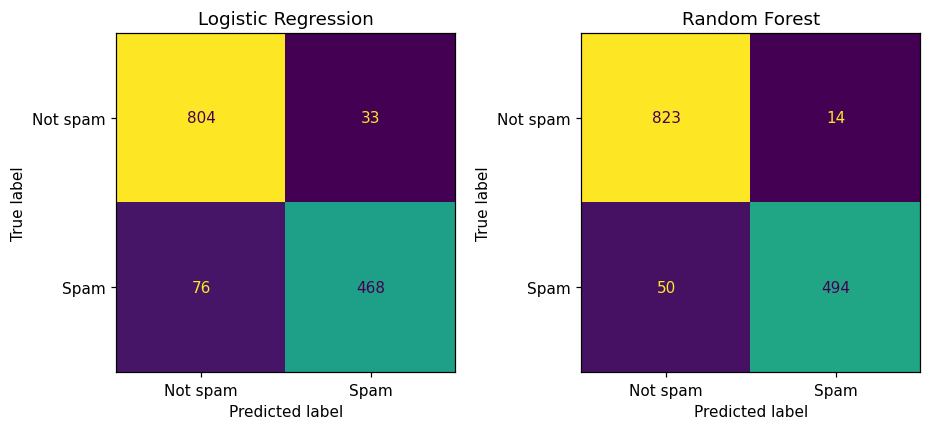

In [18]:
# confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=["Not spam", "Spam"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.show()

In [19]:
# accuracy, precision, recall, F1 and ROC-AUC (positive class = spam)
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1-score": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, prob)})

test_results = pd.DataFrame(rows).set_index("Model")
test_results.round(4)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.9211,0.9341,0.8603,0.8957,0.9678
Random Forest,0.9537,0.9724,0.9081,0.9392,0.9847


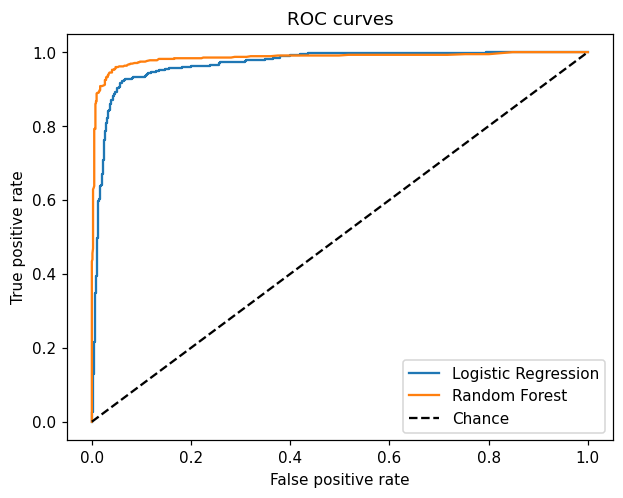

In [20]:
# ROC curves
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="Chance")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend()
plt.show()

## 4. 5-fold stratified cross-validation (2 marks)

In [21]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metrics = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_means, cv_stds = {}, {}
for name, model in models.items():
    scores = cross_validate(model, X, y, cv=skf, scoring=metrics)
    cv_means[name] = {m: scores["test_" + m].mean() for m in metrics}
    cv_stds[name] = {m: scores["test_" + m].std() for m in metrics}

print("Mean over 5 folds:")
display_means = pd.DataFrame(cv_means).T.round(4)
display_means

Mean over 5 folds:


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.9265,0.9238,0.8869,0.9049,0.9712
Random Forest,0.9533,0.9545,0.9255,0.9398,0.9867


In [22]:
print("Standard deviation over 5 folds:")
pd.DataFrame(cv_stds).T.round(4)

Standard deviation over 5 folds:


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.0084,0.0149,0.0093,0.0105,0.0049
Random Forest,0.0075,0.0110,0.0087,0.0096,0.0025


## 5. Recommendation (3 marks)
*(A4 is not in this notebook. I assumed the key metric is **precision on the spam class**, because a real email wrongly sent to spam is worse than a spam email getting through. Change this if your A4 says something else.)*

**I recommend Random Forest.** It is better on every test metric: accuracy 0.954 vs 0.921, precision 0.972 vs 0.934, recall 0.908 vs 0.860 and ROC-AUC 0.985 vs 0.968. Cross-validation gives the same ranking, and the gaps are bigger than the fold-to-fold standard deviation (about 0.01).

For precision, Random Forest wrongly flagged only 14 real emails as spam, against 33 for Logistic Regression. It also missed fewer spam emails (50 vs 76). It does better because it can capture non-linear patterns in the word-frequency features. The downside is that it is harder to interpret; if explaining the model mattered more, Logistic Regression would be the fallback.

---
# C3. Clustering on Glass Identification (ignore type) — 10 marks

In [23]:
# C3 imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

SEED = 7863

## 1. Select features, remove label, standardise (2 marks)

In [24]:
glass = pd.read_csv("glass.csv")
print("Shape:", glass.shape, " Missing values:", glass.isna().sum().sum())

# 'Type' is the class label, so drop it. The remaining columns are all numeric.
features = glass.drop(columns="Type")
print("Features used:", list(features.columns))

# standardise so every feature has mean 0 and std 1
X_scaled = StandardScaler().fit_transform(features)

Shape: (214, 10)  Missing values: 0
Features used: ['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']


## 2. k-means for k = 2 to 8 (3 marks)

In [25]:
k_values = range(2, 9)
inertias = []
silhouettes = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

scores = pd.DataFrame({"k": k_values, "Inertia": inertias, "Silhouette": silhouettes}).set_index("k")
scores.round(4)

,Inertia,Silhouette
k,,
2,1526.2794,0.4475
3,1239.1029,0.3685
4,1036.5917,0.3910
5,888.2083,0.3217
6,770.9793,0.3324
7,682.1004,0.3385
8,609.9200,0.3578


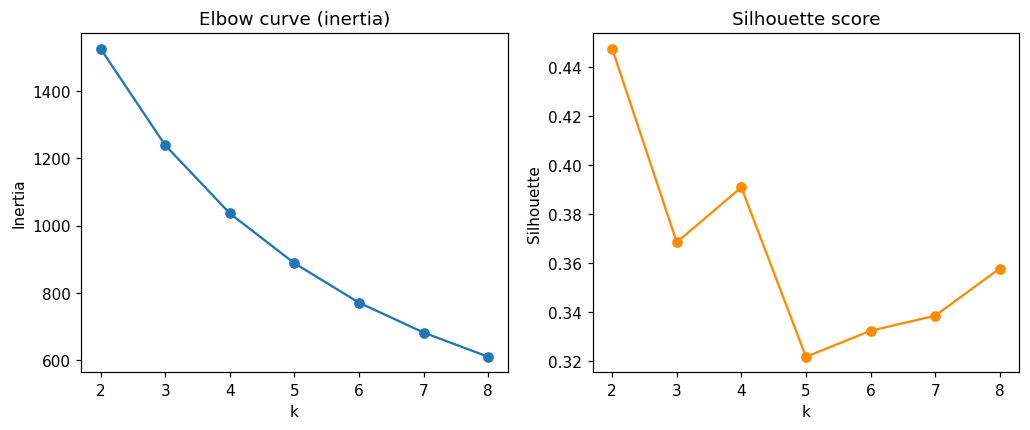

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].plot(k_values, inertias, "o-")
ax[0].set_title("Elbow curve (inertia)")
ax[0].set_xlabel("k")
ax[0].set_ylabel("Inertia")

ax[1].plot(k_values, silhouettes, "o-", color="darkorange")
ax[1].set_title("Silhouette score")
ax[1].set_xlabel("k")
ax[1].set_ylabel("Silhouette")

plt.show()

## 3. Choosing k (2 marks)

**I choose k = 4.**
- **Elbow:** there is no sharp elbow, but the drop in inertia gets smaller after k = 4 (about 287, then 202, then 148 for the next steps), so extra clusters give less and less.
- **Silhouette:** k = 2 scores highest (0.448), but it only splits the glasses into 181 and 33, which is too coarse to be useful. After k = 2 the score drops at k = 3 (0.369) and goes back up to 0.391 at k = 4, which is the best score among the options with more than two clusters.

The downside is that one cluster at k = 4 is tiny (2 glasses). If only the highest silhouette mattered, k = 2 would be chosen.

## 4. Cluster profiles, PCA plot and description (3 marks)

In [27]:
chosen_k = 4
kmeans = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10)
raw_labels = kmeans.fit_predict(X_scaled)

# number the clusters by size so that cluster 0 is the biggest
size_order = pd.Series(raw_labels).value_counts().index
new_number = {old: new for new, old in enumerate(size_order)}
labels = pd.Series(raw_labels).map(new_number).values

In [28]:
# profile: mean of each feature per cluster (original units)
profile = features.copy()
profile["Cluster"] = labels
cluster_means = profile.groupby("Cluster").mean()
cluster_means["Size"] = profile.groupby("Cluster").size()
cluster_means.round(3)

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Size
Cluster,,,,,,,,,,
0,1.517,13.173,3.400,1.383,72.810,0.563,8.445,0.019,0.059,138
1,1.523,13.334,2.112,1.097,72.053,0.243,10.907,0.081,0.082,45
2,1.517,14.669,0.356,2.170,72.963,0.182,8.505,1.075,0.013,29
3,1.513,13.010,0.000,3.030,70.590,6.210,6.945,0.000,0.000,2


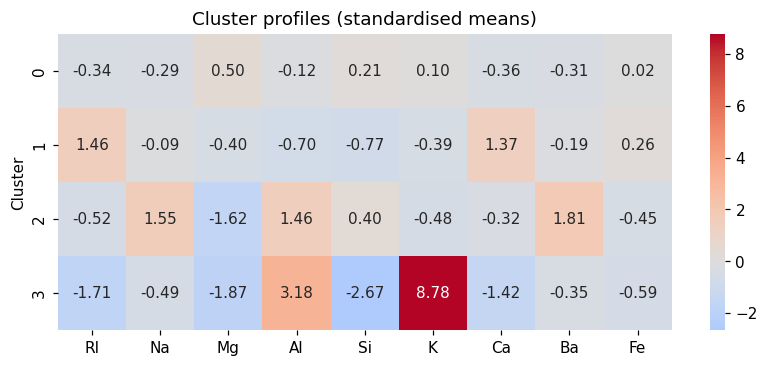

In [29]:
# same profile as z-scores: shows which features are above (+) or below (-) average
z_means = pd.DataFrame(X_scaled, columns=features.columns).groupby(labels).mean()

plt.figure(figsize=(9, 3.5))
sns.heatmap(z_means, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster profiles (standardised means)")
plt.ylabel("Cluster")
plt.show()

Variance explained by the 2 components: 50.7%


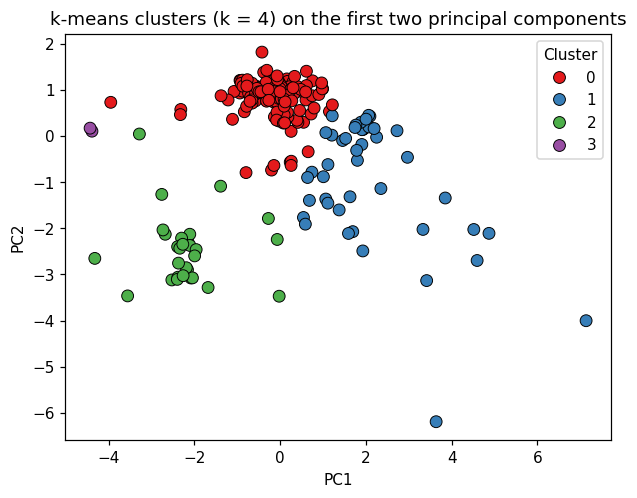

In [30]:
# 2-D PCA plot
pca = PCA(n_components=2, random_state=SEED)
pcs = pca.fit_transform(X_scaled)
print("Variance explained by the 2 components: %.1f%%" % (pca.explained_variance_ratio_.sum() * 100))

sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=labels, palette="Set1", s=60, edgecolor="k")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("k-means clusters (k = 4) on the first two principal components")
plt.legend(title="Cluster")
plt.show()

### Cluster descriptions
*(Clusters are numbered by size. If you change k, re-check these against the tables above.)*

- **Cluster 0 (138 glasses, ~64%) – ordinary glass.** Close to average on most features, with fairly high magnesium (about 3.4) and almost no barium. This is the typical glass in the data.
- **Cluster 1 (45 glasses) – calcium-rich glass.** Highest calcium (about 10.9) and highest refractive index, with low aluminium and silicon.
- **Cluster 2 (29 glasses) – barium glass.** Highest sodium (about 14.7) and barium (about 1.1), above-average aluminium and almost no magnesium (about 0.4).
- **Cluster 3 (2 glasses) – outliers.** Extremely high potassium (about 6.2 vs an average of 0.5), the highest aluminium, no magnesium and low silicon. These two glasses are very unusual.

The two PCA components explain only about 51% of the variance, so some overlap on the 2-D plot is expected.